# Reply timing

**Does the earlier reply win more often within a published pair?** Measure the time from the original post to each top-level opening reply using the archived `created_utc` timestamps. Both replies in a pair share the same OP post. Equal timestamps are ties. Missing or negative delays exclude the pair from the timing analysis.

The [feature script](analyze_reply_timing.py) extracts durations from the training metadata Parquet files. The [model script](../models/train_p2_plus_reply_timing.py) adds the signed A-minus-B difference in `log1p(delay in minutes)` to the original P2 inputs. The log compresses long delays and preserves zero-minute delays.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
ROOT = REPO / "project/data/processed/linguistic-features"
MODEL_RUN_ID = "20261120T215323283056Z"
model_run = ROOT / "paired-models/p2_plus_reply_timing" / MODEL_RUN_ID
model_report = json.loads((model_run / "results.json").read_text())
timing_run = ROOT / "reply-timing" / model_report["timing_input_run"]
report = json.loads((timing_run / "results.json").read_text())
scores_path = timing_run / "paired_scores.parquet"
assert report["split"] == model_report["split"] == "train"
assert hashlib.sha256(scores_path.read_bytes()).hexdigest() == model_report["timing_input_sha256"]
scores = pd.read_parquet(scores_path)
openings = pd.read_parquet(timing_run / "opening_scores.parquet")
assert scores.groupby("post_id")["fold"].nunique().eq(1).all()
print(f"{len(scores):,} usable training pairs across {report['discussions']:,} OP discussions")
print(f"{report['pairs_missing_valid_delay']:,} pairs missing a valid delay")
display(openings["reply_delay_minutes"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2).to_frame())

3,451 usable training pairs across 2,507 OP discussions
0 pairs missing a valid delay


,reply_delay_minutes
count,6581.00
mean,268.32
std,707.27
min,1.63
25%,37.50
50%,104.93
75%,298.38
95%,944.97
99%,1872.04
max,24503.85


## Earlier-reply win rate

Report ties separately and calculate the earlier-reply win rate among pairs with different timestamps. The gap is how far apart the two replies were posted. Intervals resample OP discussions within each reported group. Like the other pair analyses, this describes associations among matched replies.

In [2]:
statistics = {"All pairs": report["all_pairs"], **report["by_gap"]}
association = pd.DataFrame([{
    "Gap": name, "Pairs": counts["pairs"], "Earlier won": counts["winner_higher"],
    "Later won": counts["winner_lower"], "Ties": counts["ties"],
    "Earlier won (%)": 100 * counts["winner_higher_rate"],
    "95% CI lower (%)": 100 * counts["ci_95"][0],
    "95% CI upper (%)": 100 * counts["ci_95"][1],
} for name, counts in statistics.items()]).set_index("Gap")
display(association.round(2))
display(pd.Series({
    "Timing-only ROC-AUC": report["prediction"]["roc_auc"],
    "Timing-only average precision": report["prediction"]["average_precision"],
}, name="Out-of-fold score").round(4).to_frame())

,Pairs,Earlier won,Later won,Ties,Earlier won (%),95% CI lower (%),95% CI upper (%)
Gap,,,,,,,
All pairs,3451,1877,1574,0,54.39,52.56,56.14
0–5 min,191,102,89,0,53.40,46.81,60.00
>5–30 min,610,295,315,0,48.36,44.32,52.83
>30–120 min,934,472,462,0,50.54,47.09,53.95
>120 min,1716,1008,708,0,58.74,56.10,61.41


,Out-of-fold score
Timing-only ROC-AUC,0.5612
Timing-only average precision,0.5539


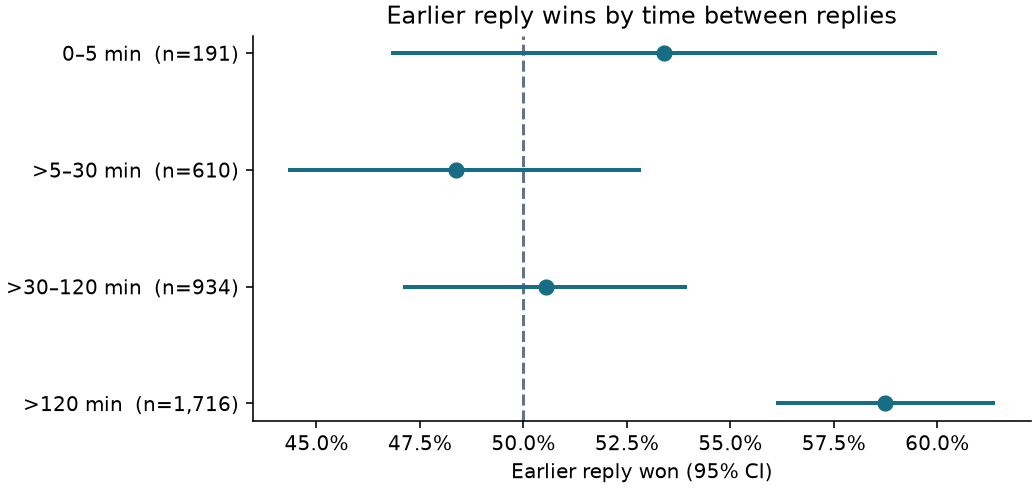

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

groups = association.drop(index="All pairs")
positions = np.arange(len(groups))
fig, ax = plt.subplots(figsize=(7.2, 3.4), layout="constrained")
ax.axvline(50, linestyle="--", color="#63748a")
ax.hlines(positions, groups["95% CI lower (%)"], groups["95% CI upper (%)"], color="#176d83", lw=2)
ax.scatter(groups["Earlier won (%)"], positions, color="#176d83", s=50, zorder=3)
ax.set_yticks(positions, [f"{gap}  (n={row['Pairs']:,.0f})" for gap, row in groups.iterrows()])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.set(title="Earlier reply wins by time between replies", xlabel="Earlier reply won (95% CI)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Incremental prediction beyond P2

Both models use the same OP-discussion-grouped training folds, with scaling fitted inside each fold. The comparison uses identical fitting and validation cohorts, even if timing data are missing. The 95% intervals use 1,000 paired OP-discussion bootstrap draws of the out-of-fold predictions. This experiment uses the published training pairs.

In [4]:
prediction = pd.read_parquet(model_run / "oof_predictions.parquet")
keys = ["pair_id", "post_id", "a_comment_id", "b_comment_id", "a_wins", "fold"]
timing = "a_minus_b_log1p_reply_delay_minutes"
pd.testing.assert_frame_equal(scores[[*keys, timing]].reset_index(drop=True),
                              prediction[[*keys, timing]].reset_index(drop=True))
baseline_run = ROOT / "paired-models/p2_word_count_and_content_word_zipf_differences" / model_report["baseline_run"]
baseline_report = json.loads((baseline_run / "results.json").read_text())
assert baseline_report["split"] == "train" and baseline_report["input_sha256"] == model_report["input_sha256"]
if not model_report["baseline_refit_on_timing_cohort"]:
    archived = pd.read_parquet(baseline_run / "oof_predictions.parquet")
    pd.testing.assert_frame_equal(prediction[keys], archived[keys])
    np.testing.assert_array_equal(prediction["p2_oof_probability_a_wins"], archived["oof_probability_a_wins"])

model_labels = ["P2", "P2 + reply timing"]
data = prediction.assign(**{
    model_labels[0]: prediction["p2_oof_probability_a_wins"],
    model_labels[1]: prediction["oof_probability_a_wins"],
})

In [5]:
from sklearn.metrics import accuracy_score, average_precision_score, log_loss, roc_auc_score


def pairwise_accuracy(y, probability, sample_weight=None):
    return accuracy_score(y, probability >= 0.5, sample_weight=sample_weight)


metric_functions = {
    "ROC-AUC": roc_auc_score,
    "Average precision": average_precision_score,
    "Pairwise accuracy": pairwise_accuracy,
    "Log loss": log_loss,
}
y = data["a_wins"].to_numpy()
p2, expanded_probability = data[model_labels].to_numpy().T
post_codes, posts = pd.factorize(data["post_id"])
rng = np.random.default_rng(42)
differences = {name: [] for name in metric_functions}
for _ in range(1000):
    post_weights = rng.multinomial(len(posts), np.full(len(posts), 1 / len(posts)))
    weights = post_weights[post_codes]
    for name, metric in metric_functions.items():
        differences[name].append(
            metric(y, expanded_probability, sample_weight=weights)
            - metric(y, p2, sample_weight=weights)
        )

rows = []
for name, metric in metric_functions.items():
    base, extra = metric(y, p2), metric(y, expanded_probability)
    low, high = np.quantile(differences[name], [0.025, 0.975])
    rows.append({
        "Metric": name, "P2": base, "P2 + reply timing": extra, "Change": extra - base,
        "95% CI lower": low, "95% CI upper": high,
    })
performance = pd.DataFrame(rows).set_index("Metric")
display(performance.round(5))

,P2,P2 + reply timing,Change,95% CI lower,95% CI upper
Metric,,,,,
ROC-AUC,0.70324,0.72380,0.02057,0.01152,0.02918
Average precision,0.69426,0.70948,0.01522,0.00608,0.02454
Pairwise accuracy,0.64677,0.66416,0.01739,0.00533,0.02967
Log loss,0.62701,0.61415,-0.01286,-0.01877,-0.00691
